# Predicción Lineal

**22.46 Procesamiento Adaptativo de Señales Aleatorias — Trabajo Práctico 3**

# Grupo N° 5

| Integrante | Legajo |
|---|---|
| Albertine Gjøs | 69531 |
| Marek Myrebøe-Engels | 69476 |

In [7]:
from scipy import signal
from scipy.linalg import solve_toeplitz
from scipy.signal.windows import hann
import numpy as np
import soundfile as sf
from IPython.display import Audio, display
import matplotlib.pyplot as plt


## 1. Grabación de Voz

In [8]:
fs = 16000

a, fs_a = sf.read("data/a.wav", always_2d=True)
sh, fs_sh = sf.read("data/sh.wav", always_2d=True)

a = a.mean(axis=1)
a = signal.resample_poly(a, fs, fs_a)
a = a[0:1*fs] # 1 segundo
display(Audio(a, rate=fs))

sh = sh.mean(axis=1)
sh = signal.resample_poly(sh, fs, fs_sh)
sh = sh[0:fs] # 1 segundo
display(Audio(sh, rate=fs))

## 2. Predicción Lineal 

Period: 82 samples
f0: 195.1219512195122 Hz
Phase: 29


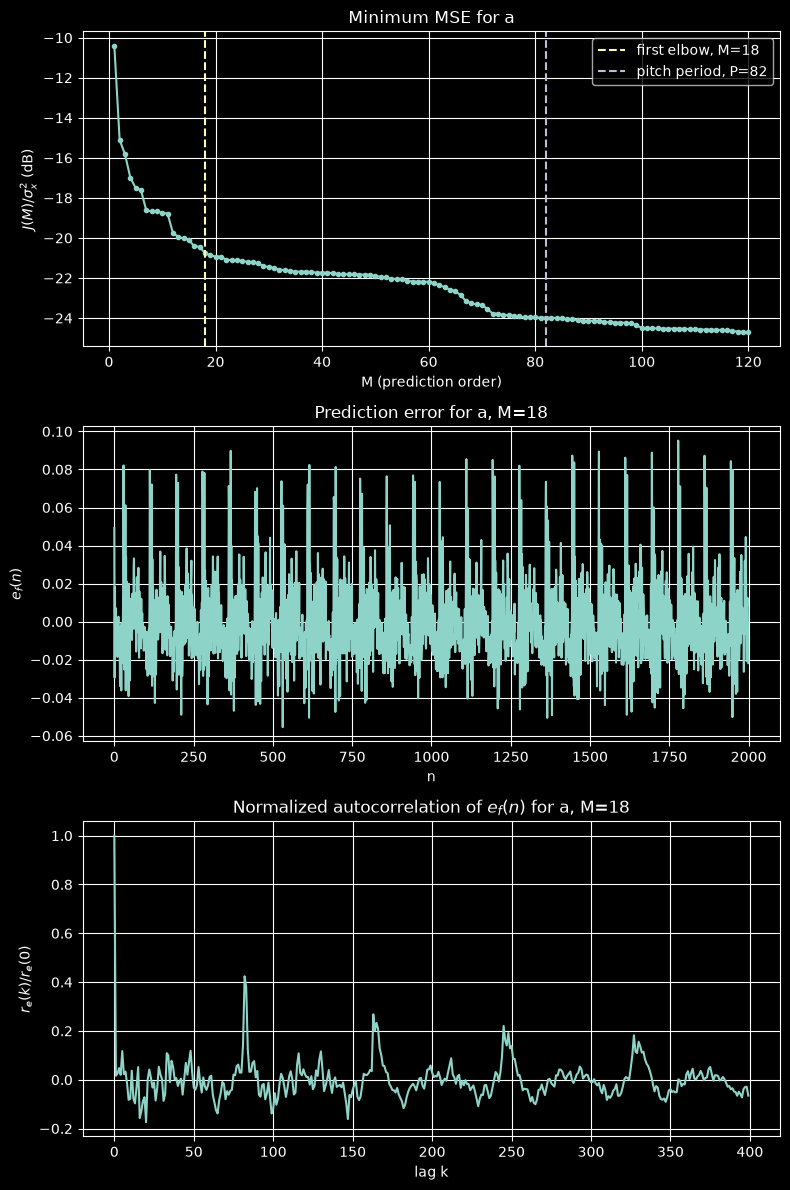

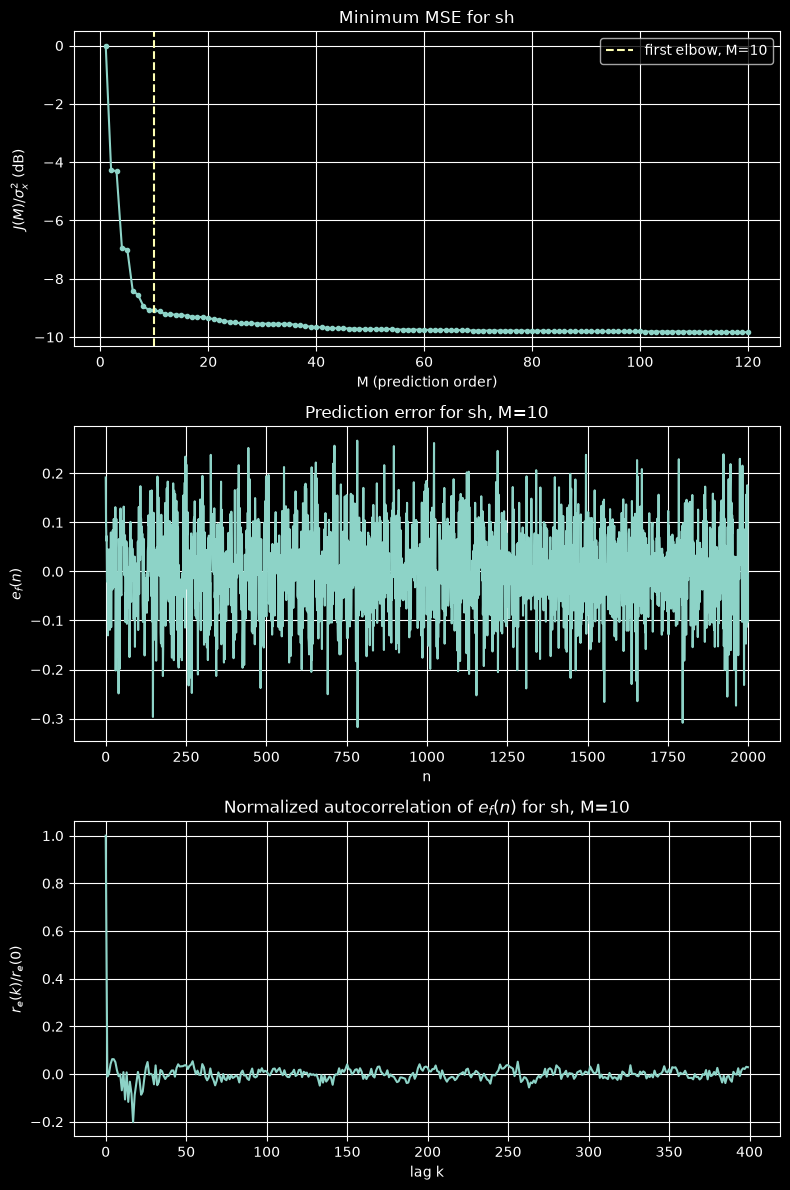

In [9]:
def forward_prediction(x, M):
    N = len(x)
    # r(k) = 1/N sum x(n) x(n-k), k = 0..M
    r = np.array([np.dot(x[:N-k], x[k:]) for k in range(M+1)]) / N
    if r[0] == 0:
        return np.zeros(M), np.zeros(N-M), 0.0

    # Wiener-Hopf: R a = -r
    ao = solve_toeplitz(r[:M], -r[1:M+1])

    # e_f(n) = x(n) + a^H x(n-1)
    A = np.concatenate(([1], ao))
    e = signal.lfilter(A, [1], x)[M:]

    # Minimum MSE: J = sigma_x^2 + r^H a
    Jo = r[0] + np.dot(r[1:M+1], ao)

    return ao, e, Jo


def find_period_and_phase(e):
    # Estimate pitch period from the autocorrelation of the error,
    # searching only lags of plausible pitch (50 - 400 Hz)
    e_centered = e - np.mean(e)
    corr = signal.correlate(e_centered, e_centered, mode="full")
    corr = corr[len(corr)//2:]
    lag_min, lag_max = fs // 400, fs // 50
    period = lag_min + np.argmax(corr[lag_min:lag_max])
    print("Period:", period, "samples")
    print("f0:", fs / period, "Hz")

    # Align the impulse train with the first pulse of e (largest value in the first period).
    # The real pitch is not exactly constant (period varies ~76-89 samples), so a fixed-period
    # train drifts away from the true pulses later on: no single phase fits the whole signal.
    phase = np.argmax(e[:period])
    print("Phase:", phase)

    return period, phase


M_values = range(1, 121)
M_FIRST = {"a": 18, "sh": 10}   # end of the first elbow

for x, name in zip([a, sh], ['a', 'sh']):

    J = np.array([forward_prediction(x, M)[2] for M in M_values])
    J_dB = 10*np.log10(J / np.mean(x**2))

    M = M_FIRST[name]
    ao, e, Jo = forward_prediction(x, M)

    fig, ax = plt.subplots(3, 1, figsize=(8, 12))
    ax[0].plot(M_values, J_dB, "-o", markersize=3)
    ax[0].axvline(M, color="C1", ls="--", label=f"first elbow, M={M}")
    if name == "a":
        period, _ = find_period_and_phase(e)
        ax[0].axvline(period, color="C2", ls="--", label=f"pitch period, P={period}")
    ax[0].set_xlabel("M (prediction order)")
    ax[0].set_ylabel(r"$J(M)/\sigma_x^2$ (dB)")
    ax[0].set_title(f"Minimum MSE for {name}")
    ax[0].legend()
    ax[0].grid()

    ax[1].plot(e[:2000])
    ax[1].set_xlabel("n")
    ax[1].set_ylabel(r"$e_f(n)$")
    ax[1].set_title(f"Prediction error for {name}, M={M}")
    ax[1].grid()

    # Autocorrelation of the error: a peak at the pitch period means e_f(n) is periodic
    e_centered = e - np.mean(e)
    corr = signal.correlate(e_centered, e_centered, mode="full")[len(e)-1:]
    ax[2].plot(corr[:400] / corr[0])
    ax[2].set_xlabel("lag k")
    ax[2].set_ylabel(r"$r_e(k)/r_e(0)$")
    ax[2].set_title(f"Normalized autocorrelation of $e_f(n)$ for {name}, M={M}")
    ax[2].grid()

    plt.tight_layout()
    plt.show()

### Answer: why two elbows for /a/ and one for /sh/

$J(M)/\sigma_x^2$ in dB:

| M | 1 | 2 | 4 | 8 | 12 | 18 | 32 | 64 | 72 | 82 | 120 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| /a/ | −10.4 | −15.1 | −17.0 | −18.7 | −19.8 | −20.7 | −21.6 | −22.6 | −23.8 | −24.0 | −24.7 |
| /sh/ | 0.0 | −4.3 | −6.9 | −8.9 | −9.2 | −9.3 | −9.5 | −9.8 | −9.8 | −9.8 | −9.8 |

Speech = an excitation (pulses or noise) passed through the vocal tract filter. Two terms we use below:
- **Formants:** the resonances of the vocal tract (throat, mouth, nose). They show up as peaks in the spectrum, and their positions decide which vowel we hear.
- **Pitch ($f_0$):** for voiced sounds like /a/, the vocal cords open and close periodically. $f_0$ is how many times per second this happens, and $P = f_s/f_0$ is the period in samples. It is how high or low the voice sounds.

- **First elbow (both, M ≈ 10–20): the vocal tract.** Each formant needs a pair of poles. With about 4–5 formants below 8 kHz, about 18 coefficients are enough. After that, $J$ stops dropping fast.
- **Second elbow (only /a/, M ≈ 64–82): the pitch.** /a/ is voiced, so $e_f(n)$ is a train of pulses, one per vocal-cord cycle. From the autocorrelation of $e_f(n)$ we find $P = 82$ samples, so $f_0 = 16000/82 \approx 195$ Hz. When $M$ gets close to $P$, the predictor can look one period back and predict the next pulse, so $J$ drops again.
- **/sh/ has one elbow** because it is noise with no period. After the first elbow $e_f(n)$ is white noise, which can't be predicted, so $J$ stays flat (around −10 dB).

## 3. Dominio de Frecuencia

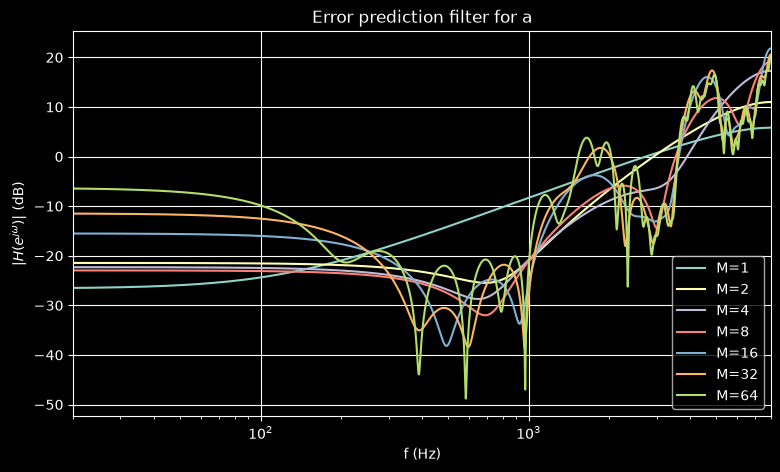

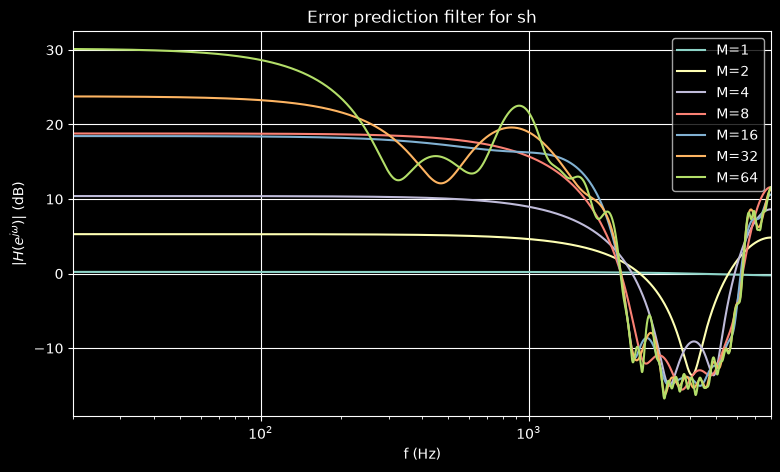

In [10]:
# Frequency response of the prediction-error filter ā (not the predictor a)
M_values = [1, 2, 4, 8, 16, 32, 64]

for x, name in zip([a, sh], ['a', 'sh']):

    plt.figure(figsize=(9, 5))

    for M in M_values:

        ao, e, J = forward_prediction(x, M)

        # Error prediction filter:
        # A(z) = 1 + a1 z^-1 + ... + aM z^-M
        A = np.concatenate(([1], ao))

        f, H = signal.freqz(A, worN=2**16, fs=fs)

        plt.semilogx(
            f,
            20*np.log10(np.maximum(np.abs(H), 1e-12)),
            label=f"M={M}"
        )

    plt.xlim(20, fs/2)
    plt.xlabel("f (Hz)")
    plt.ylabel(r"$|H(e^{j\omega})|$ (dB)")
    plt.title(f"Error prediction filter for {name}")
    plt.legend()
    plt.grid()
    plt.show()

### Answer: frequency response of the error filter

The error filter makes the error white, so $|H(e^{j\omega})| \approx \sqrt{J / S_x(e^{j\omega})}$: it is roughly **the inverse of the signal's spectrum**. It has valleys where the signal has a lot of energy (the formants).

**/a/**
- **M = 1:** $a_1 \approx -0.95$, a simple high-pass. /a/ has most of its energy at low frequencies.
- **M = 2–8:** valleys appear at the strongest formants.
- **M = 16:** valleys at ≈ 490 Hz, 930 Hz, 2.95 kHz and 5.6 kHz, the formants of /a/. The envelope is done (end of the first elbow).
- **M = 32, 64:** small valleys spaced ≈ 195 Hz $= f_0$ appear. The filter starts to remove the pitch harmonics (start of the second elbow).

**/sh/**
- **M = 1:** $a_1 \approx 0.03$, so $|H| \approx 1$. The filter does nothing.
- **M = 2–8:** a wide valley forms at 3–4.5 kHz, where the /sh/ energy is.
- **M = 16–64:** only small random ripples. There are no harmonics because /sh/ has no pitch.

## 4. Resinteticar y Filtrar

We use $M$ at the end of the first elbow: M = 18 for /a/ and M = 10 for /sh/. That way the filter models only the vocal tract, and the pitch stays in the error.

Period: 82 samples
f0: 195.1219512195122 Hz
Phase: 29
Original a


Resynthesized a, M=18


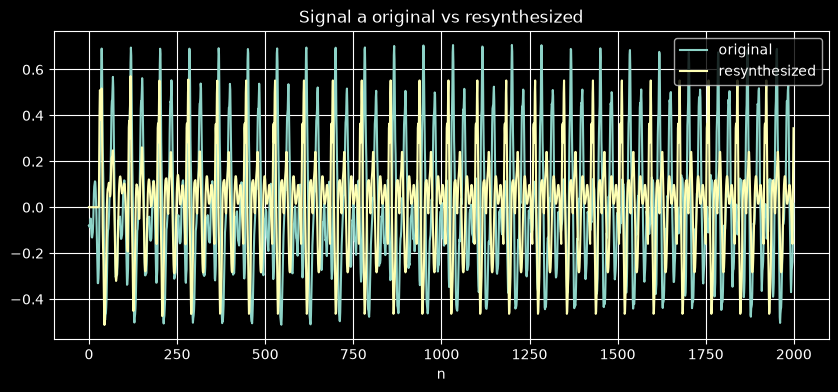

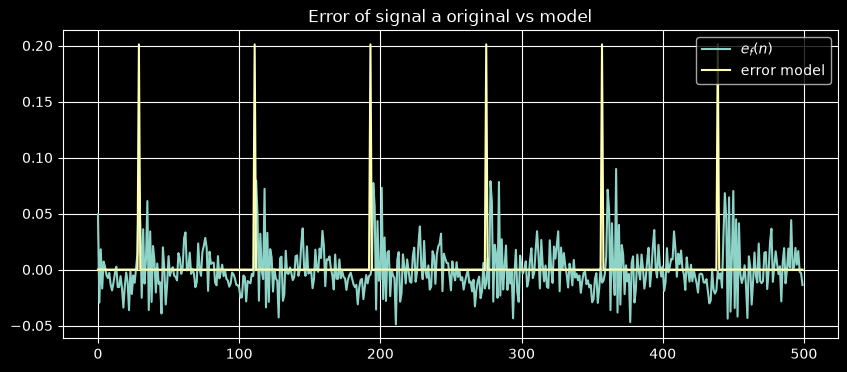

Original sh


Resynthesized sh, M=10


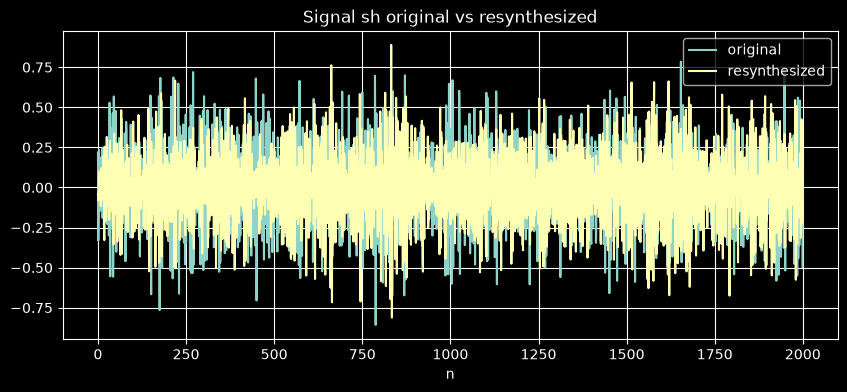

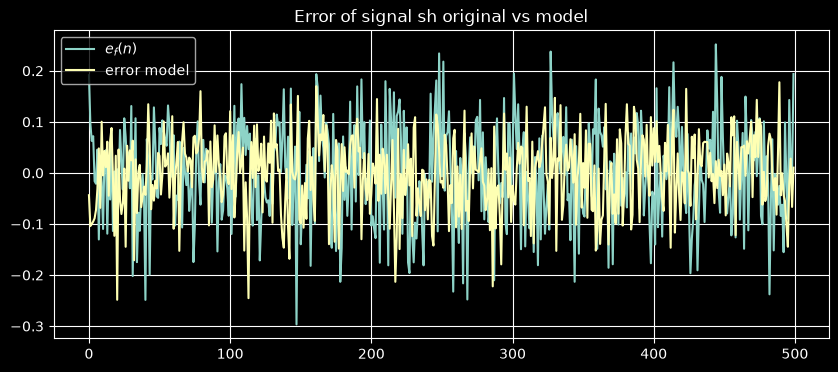

In [11]:
def error_model(e, name):
    if name == "a":
        # Voiced: impulse train at the pitch period, aligned with the error peaks
        period, phase = find_period_and_phase(e)
        e_model = np.zeros(len(e))
        e_model[phase::period] = 1
        # Match the power of the prediction error (one impulse per period).
        # Each impulse carries the energy of a whole glottal pulse (spread over several
        # samples in e_f) in a single sample, so it is taller than the peaks of e_f.
        e_model *= np.sqrt(period * np.mean(e**2))
    elif name == "sh":
        # Unvoiced: white noise
        e_model = np.random.randn(len(e))
        # Match RMS of prediction error
        e_model *= np.sqrt(np.mean(e**2) / np.mean(e_model**2))

    return e_model


for x, name in zip([a, sh], ['a', 'sh']):
    M = M_FIRST[name]
    ao, e, Jo = forward_prediction(x, M)
    A = np.concatenate(([1], ao))

    e_model = error_model(e, name)
    x_model = signal.lfilter([1], A, e_model)
    print(f"Original {name}")
    display(Audio(x, rate=fs))

    print(f"Resynthesized {name}, M={M}")
    display(Audio(x_model, rate=fs))

    Nplot = min(2000, len(x_model))
    plt.figure(figsize=(10, 4))
    plt.plot(x[M:M+Nplot], label="original")
    plt.plot(x_model[:Nplot], label="resynthesized")
    plt.xlabel("n")
    plt.legend()
    plt.title(f"Signal {name} original vs resynthesized")
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(e[:500], label=r"$e_f(n)$")
    plt.plot(e_model[:500], label="error model")
    plt.legend()
    plt.title(f"Error of signal {name} original vs model")
    plt.grid()
    plt.show()

### Answer: resynthesis vs. original

**Error model:**
- **/a/:** an impulse train with period $P = 82$ samples, aligned with the first pulse of $e_f(n)$, with the same power as $e_f(n)$. The impulses look taller than the error peaks (≈ 0.20 vs ≈ 0.09) because one sample has to carry the energy of a whole pulse. The real period changes between 76 and 89 samples, so the train slowly gets out of step with the real pulses.
- **/sh/:** white noise with the same power as $e_f(n)$.

Then we filter with $1/A(z)$. It is always stable with the autocorrelation method.

**/sh/:** sounds almost the same as the original, because the real error already is white noise.

**/a/:** you can hear the vowel, but it sounds **robotic**, because:
1. The pitch is perfectly constant. A real voice varies a little all the time.
2. A real glottal pulse is smoother than a single impulse, so the model sounds a bit metallic.
3. The noise in the real error is thrown away, so the voice loses its breathiness.

## 5. Grabación Larga

In [12]:
voice, fs_voice = sf.read("data/voice.wav", always_2d=True)
voice = voice.mean(axis=1)
voice = signal.resample_poly(voice, fs, fs_voice)
voice = voice[fs:6*fs] # 5 segundos
display(Audio(voice, rate=fs))


L = int(0.05 * fs)     # 50 ms
D = L // 2             # 50% overlap
M = 12

# Periodic Hann: shifted copies with 50% overlap sum to a constant (COLA)
w = hann(L, sym=False)

output = np.zeros(len(voice))
starts = range(0, len(voice) - L + 1, D)

period = int(fs / 160) # 100 samples

for s in starts:
    # Extract block
    seg = voice[s:s+L]
    # Hann window
    seg_w = seg * w
    # Forward prediction
    ao, e, Jo = forward_prediction(seg_w, M)
    # Error prediction filter
    A = np.concatenate(([1], ao))
    # Global 160 Hz impulse train (coherent between blocks)
    global_indices = np.arange(s, s+L)

    e_model = np.zeros(L)
    e_model[global_indices % period == 0] = 1
    # Match RMS of this block
    e_model *= np.sqrt(np.mean(e**2) / np.mean(e_model**2))
    # Inverse error prediction filter
    synthesized = signal.lfilter([1], A, e_model)
    # Window synthesized block
    synthesized_w = synthesized * w
    # Overlap-add
    output[s:s+L] += synthesized_w

display(Audio(output, rate=fs))

### Answer: long recording (M = 12, 50 ms Hann, 50 % overlap, 160 Hz)

**What we hear:** the words can still be understood, but the voice is **robotic and monotone** at a fixed 160 Hz (lower than the speaker's ≈ 195–200 Hz).

- **Why it is understandable:** the words are carried by the formants. Each 50 ms block gets its own filter, so the formants follow the speech.
- **Why it sounds robotic:** the excitation is always the same pulse train. Intonation is lost, and consonants like /s/ or /sh/ get pulses instead of noise, so they sound buzzy.
- **Why the pulse train must be coherent between blocks:** if every block restarted its own train, the pulses of overlapping blocks would not line up, and we would hear clicks.
- **Why Hann with 50 % overlap:** these windows add up to a constant, so the blocks blend smoothly without jumps in volume.